# Power System Load Type Classification

## 1. Problem Understanding

**Goal:** predict the `Load_Type` of a power system: `Light_Load`, `Medium_Load` or `Maximum_Load`.

**Data:** 15-minute readings for 2018: energy usage, reactive power, CO2, power factors and time.

**Type of problem:** 3-class classification.

**Validation (from the problem statement):** the **last month (December) is the test set**.
The model is trained on January to November and evaluated on December.

**Metrics:** accuracy, precision, recall, F1-score and confusion matrix.

## 2. Import Libraries

In [1]:
# ==========================================
# CELL 1: IMPORT LIBRARIES
# ==========================================

import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning

# Logistic regression WITHOUT scaling is trained only as a comparison.
# It does not converge (this is part of the evidence that scaling is needed),
# and it prints the same long warning in every fold, so we hide only this warning type.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Fixed random seed so results are the same every time the notebook is run
RANDOM_STATE = 42

# Train and test periods. The problem statement asks for the last month (December) as the test set.
TRAIN_START = "2018-01-01 00:00"
TRAIN_END = "2018-11-30 23:59"
TEST_START = "2018-12-01 00:00"
TEST_END = "2018-12-31 23:59"

# Class order used in reports and plots (from lowest to highest load)
LABELS = ["Light_Load", "Medium_Load", "Maximum_Load"]

## 3. Load Dataset

In [2]:
# ==========================================
# CELL 2: LOAD DATASET
# ==========================================

# Load the electricity readings so we can inspect and prepare them.
# A relative path is used so the notebook works on any machine.
# The notebook is inside the notebooks/ folder, so the data folder is one level up.
df = pd.read_csv("../data/load_data.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


## 4. Understand Dataset

In [3]:
# ==========================================
# CELL 3: CHECK COLUMN TYPES
# ==========================================

# Check data types and how many non-empty values each column has
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB


In [4]:
# ==========================================
# CELL 4: SUMMARY STATISTICS
# ==========================================

# Min / max values help us spot impossible values (for example power factor above 100%)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Usage_kWh,33482.0,30.873061,41.415015,0.0,3.310,5.29,53.560000,435.019069
Lagging_Current_Reactive.Power_kVarh,34165.0,14.704573,20.342721,0.0,2.340,5.18,23.510000,262.630718
Leading_Current_Reactive_Power_kVarh,33885.0,4.386097,9.090181,0.0,0.000,0.00,2.298558,78.809000
CO2(tCO2),34586.0,0.012947,0.019726,0.0,0.000,0.00,0.020000,0.188166
Lagging_Current_Power_Factor,34691.0,90.740871,39.745395,0.0,66.295,90.08,100.000000,299.996814
Leading_Current_Power_Factor,33570.0,94.926552,49.826872,0.0,99.800,100.00,100.000000,299.969494
NSM,34586.0,48013.664032,34046.492333,0.0,22500.000,45000.00,68400.000000,248821.810465


In [5]:
# ==========================================
# CELL 5: CHECK MISSING VALUES
# ==========================================

# Count missing values in each column so we know what needs to be handled
print(df.isna().sum())

Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64


In [6]:
# ==========================================
# CELL 6: CHECK CLASS DISTRIBUTION
# ==========================================

# Check if the classes are balanced. If one class is much bigger,
# accuracy alone can be misleading.
print(df["Load_Type"].value_counts())
print()
print(df["Load_Type"].value_counts(normalize=True).round(3))

Load_Type
Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64

Load_Type
Light_Load      0.516
Medium_Load     0.277
Maximum_Load    0.208
Name: proportion, dtype: float64


**Observations**
- Every numeric column has missing values; the target has none.
- Power factor is a percentage, so values above 100 are impossible.
- `NSM` (seconds from midnight) should be at most 86,399, but the maximum is much higher.
- Classes are imbalanced (`Light_Load` is about half), so **macro F1** is the main metric.
  Macro F1 gives each class equal weight.

## 5. Data Cleaning

In [7]:
# ==========================================
# CELL 7: RENAME COLUMNS AND PARSE DATES
# ==========================================

# Shorter column names make the rest of the code easier to read
df = df.rename(columns={
    "Date_Time": "date_time",
    "Usage_kWh": "usage_kwh",
    "Lagging_Current_Reactive.Power_kVarh": "lagging_kvarh",
    "Leading_Current_Reactive_Power_kVarh": "leading_kvarh",
    "CO2(tCO2)": "co2",
    "Lagging_Current_Power_Factor": "lagging_pf",
    "Leading_Current_Power_Factor": "leading_pf",
    "NSM": "nsm",
    "Load_Type": "load_type",
})

# Convert text dates to real datetimes. The format is day-month-year,
# so we give it explicitly to avoid days and months being swapped.
df["date_time"] = pd.to_datetime(df["date_time"], format="%d-%m-%Y %H:%M")

In [8]:
# ==========================================
# CELL 8: CHECK MIDNIGHT TIMESTAMPS
# ==========================================

# Look at the rows around the first midnight in the original file order
df.iloc[93:97]

,date_time,usage_kwh,lagging_kvarh,leading_kvarh,co2,lagging_pf,leading_pf,nsm,load_type
93,2018-01-01 23:30:00,3.24,2.950000,0.0,0.0,117.036715,100.00000,84600.0,Light_Load
94,2018-01-01 23:45:00,NaN,6.406411,0.0,0.0,67.970000,100.00000,85500.0,Light_Load
95,2018-01-01 00:00:00,3.42,3.460000,0.0,0.0,70.300000,291.49819,0.0,Light_Load
96,2018-01-02 00:15:00,3.20,3.100000,0.0,0.0,71.820000,100.00000,900.0,Light_Load


The file goes `01-01-2018 23:45` -> `01-01-2018 00:00` -> `02-01-2018 00:15`.
So a `00:00` reading is written with the date of the day that just **ended**:
`01-01-2018 00:00` is really midnight at the start of **2 January**.
We add one day to every `00:00` timestamp. This must happen **before** sorting,
before creating weekday/month features and before the train/test split.

In [9]:
# ==========================================
# CELL 9: FIX MIDNIGHT TIMESTAMPS
# ==========================================

# Find all readings at exactly 00:00 and move them to the next day
is_midnight = (df["date_time"].dt.hour == 0) & (df["date_time"].dt.minute == 0)
print("Midnight rows fixed:", is_midnight.sum())

df.loc[is_midnight, "date_time"] = df.loc[is_midnight, "date_time"] + pd.Timedelta(days=1)
print("Date range:", df["date_time"].min(), "to", df["date_time"].max())

Midnight rows fixed: 365
Date range: 2018-01-01 00:15:00 to 2019-01-01 00:00:00


In [10]:
# ==========================================
# CELL 10: CHECK DUPLICATES
# ==========================================

# Exact duplicate rows would give the model the same example twice
print("Exact duplicate rows:", df.duplicated().sum())

# Each 15-minute timestamp should appear only once
print("Duplicate timestamps:", df["date_time"].duplicated().sum())

# Show the rows that share a timestamp so we can decide which one to keep
df[df["date_time"].duplicated(keep=False)]

Exact duplicate rows: 0
Duplicate timestamps: 1


,date_time,usage_kwh,lagging_kvarh,leading_kvarh,co2,lagging_pf,leading_pf,nsm,load_type
35023,2018-12-31 20:00:00,4.14,0.0,20.09,0.0,100.00000,20.18,72000.0,Light_Load
35040,2018-12-31 20:00:00,NaN,0.0,20.10,0.0,217.27347,20.19,72000.0,Light_Load


One timestamp appears twice. The second copy (last row of the file) has a missing `usage_kwh`
and an impossible power factor (217), so it looks corrupted. We keep the first copy.
This is done **before sorting**, so the original file order decides which copy is kept.

In [11]:
# ==========================================
# CELL 11: REMOVE DUPLICATE TIMESTAMP AND SORT BY TIME
# ==========================================

# Keep the first (clean) reading for the duplicated timestamp
df = df.drop_duplicates(subset="date_time", keep="first")
print("Rows after removing duplicate:", len(df))

# After the midnight fix the file should already be in time order. We check it and sort anyway,
# because cross-validation and the train/test split are based on time.
out_of_order = df["date_time"].diff() < pd.Timedelta(0)
print("Rows out of time order:", out_of_order.sum())

df = df.sort_values("date_time").reset_index(drop=True)

# Every reading should be exactly 15 minutes after the previous one (no gaps, no wrong dates)
print("Time steps between readings:")
print(df["date_time"].diff().value_counts())

Rows after removing duplicate: 35040
Rows out of time order: 0
Time steps between readings:
date_time
0 days 00:15:00    35039
Name: count, dtype: int64


Every step is exactly 15 minutes, so the midnight fix is correct. The last reading is now
`2019-01-01 00:00` (midnight at the end of 31 December). It is outside both the training period
and the test period, so it is not used.

In [12]:
# ==========================================
# CELL 12: FIX NSM (SECONDS FROM MIDNIGHT)
# ==========================================

# NSM should be the number of seconds since midnight for each timestamp.
# We calculate the correct value from the timestamp and compare.
correct_nsm = df["date_time"].dt.hour * 3600 + df["date_time"].dt.minute * 60

nsm_is_wrong = df["nsm"].notna() & (df["nsm"] != correct_nsm)
print("NSM missing:", df["nsm"].isna().sum())
print("NSM not matching the timestamp:", nsm_is_wrong.sum())

# The timestamp is reliable, so we replace NSM with the correct value
df["nsm"] = correct_nsm

NSM missing: 455
NSM not matching the timestamp: 3414


In [13]:
# ==========================================
# CELL 13: FIX IMPOSSIBLE POWER FACTOR VALUES
# ==========================================

# Power factor is a percentage (0-100). Values above 100 are measurement errors,
# so we mark them as missing and let the imputer fill them later.
print("lagging_pf above 100:", (df["lagging_pf"] > 100).sum())
print("leading_pf above 100:", (df["leading_pf"] > 100).sum())

df.loc[df["lagging_pf"] > 100, "lagging_pf"] = None
df.loc[df["leading_pf"] > 100, "leading_pf"] = None

lagging_pf above 100: 3225
leading_pf above 100: 2685


In [14]:
# ==========================================
# CELL 14: CHECK FOR CORRUPTED VALUES
# ==========================================

# The original readings are recorded with 2 decimals, but some values have many more decimals.
# Only the training period (Jan-Nov) is used for this analysis.
training_period = df[(df["date_time"] >= TRAIN_START) & (df["date_time"] <= TRAIN_END)]

for column in ["usage_kwh", "lagging_kvarh", "leading_kvarh", "co2"]:
    values = training_period[column]
    has_extra_decimals = values.notna() & (values.round(2) != values)

    # Compare each value with the average of the reading before and after it.
    # Normal readings should be close to their neighbours (ratio about 1).
    neighbour_average = (values.shift(1) + values.shift(-1)) / 2
    ratio = values / neighbour_average
    has_neighbours = neighbour_average > 0

    print(column)
    print("   values with extra decimals:", has_extra_decimals.sum(),
          "(" + str(round(100 * has_extra_decimals.mean(), 1)) + "%)")
    print("   median ratio to neighbours - extra decimals:",
          round(ratio[has_extra_decimals & has_neighbours].median(), 2),
          "| normal values:", round(ratio[~has_extra_decimals & has_neighbours].median(), 2))

usage_kwh
   values with extra decimals: 3059 (9.5%)
   median ratio to neighbours - extra decimals: 2.03 | normal values: 0.98
lagging_kvarh
   values with extra decimals: 2496 (7.8%)
   median ratio to neighbours - extra decimals: 2.08 | normal values: 0.97
leading_kvarh
   values with extra decimals: 971 (3.0%)
   median ratio to neighbours - extra decimals: 2.1 | normal values: 0.94
co2
   values with extra decimals: 1288 (4.0%)
   median ratio to neighbours - extra decimals: 2.09 | normal values: 1.0


In [15]:
# ==========================================
# CELL 15: CHECK USING THE POWER FACTOR FORMULA
# ==========================================

# Power factor can be calculated from energy and reactive power:
#   power factor = 100 * kWh / sqrt(kWh^2 + kVarh^2)
# If the recorded values are correct, the calculated and recorded power factor should match.
usage = training_period["usage_kwh"]
kvarh = training_period["lagging_kvarh"]
expected_pf = 100 * usage / (usage ** 2 + kvarh ** 2) ** 0.5
pf_difference = (expected_pf - training_period["lagging_pf"]).abs()

usage_extra_decimals = usage.notna() & (usage.round(2) != usage)
kvarh_extra_decimals = kvarh.notna() & (kvarh.round(2) != kvarh)
both_normal = ~usage_extra_decimals & ~kvarh_extra_decimals
can_check = pf_difference.notna()

print("Share of rows where the formula is off by more than 1 point:")
print("   usage and kVarh normal:     ", round((pf_difference[both_normal & can_check] > 1).mean(), 3))
print("   usage has extra decimals:   ", round((pf_difference[usage_extra_decimals & can_check] > 1).mean(), 3))
print("   kVarh has extra decimals:   ", round((pf_difference[kvarh_extra_decimals & can_check] > 1).mean(), 3))
print()
print("Rows with difference between 0.05 and 1 point:", round(((pf_difference > 0.05) & (pf_difference <= 1)).mean(), 4))
print("Rows with difference above 1 point:           ", round((pf_difference > 1).mean(), 4))

Share of rows where the formula is off by more than 1 point:
   usage and kVarh normal:      0.008
   usage has extra decimals:    0.736
   kVarh has extra decimals:    0.955

Rows with difference between 0.05 and 1 point: 0.0047
Rows with difference above 1 point:            0.1264


**Finding: some measurements are genuinely corrupted.**
- Values with extra decimals are about **2x their neighbouring readings**, while normal values are about 1x.
- For rows with normal usage and kVarh, the power factor formula matches in over 99% of rows.
  For rows with extra-decimal usage (74%) or kVarh (96%) it does not. This check uses only the values in the same row (no future readings).
- The formula difference is either tiny (rounding) or large, with almost nothing in between, so a
  **1-point threshold** cleanly separates consistent and inconsistent rows (based on the training period only).

**Decision:** we do not remove or change these values here. Setting them to missing would discard many
measurements. In section 10 we test with cross-validation (training period only) whether marking
inconsistent rows as missing helps the model, and decide based on that.

In [16]:
# ==========================================
# CELL 16: REMAINING MISSING VALUES
# ==========================================

# These missing values are NOT filled here.
# They are filled later with the median of the TRAINING data only (inside the pipeline),
# so no information from the test month leaks into training.
print(df.isna().sum())

date_time           0
usage_kwh        1558
lagging_kvarh     876
leading_kvarh    1156
co2               455
lagging_pf       3575
leading_pf       4156
nsm                 0
load_type           0
dtype: int64


## 6. Exploratory Data Analysis

**All EDA below uses only the training period (January-November).**
December is the test set, so it must not influence any decision about features or models.

In [17]:
# ==========================================
# CELL 17: ADD HOUR, DAY AND MONTH FOR EDA
# ==========================================

# Simple time columns used to explore patterns
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek   # 0 = Monday, 6 = Sunday
df["month"] = df["date_time"].dt.month

# EDA data = training period only
eda_data = df[(df["date_time"] >= TRAIN_START) & (df["date_time"] <= TRAIN_END)]
print("EDA rows (Jan-Nov):", len(eda_data))

EDA rows (Jan-Nov): 32063


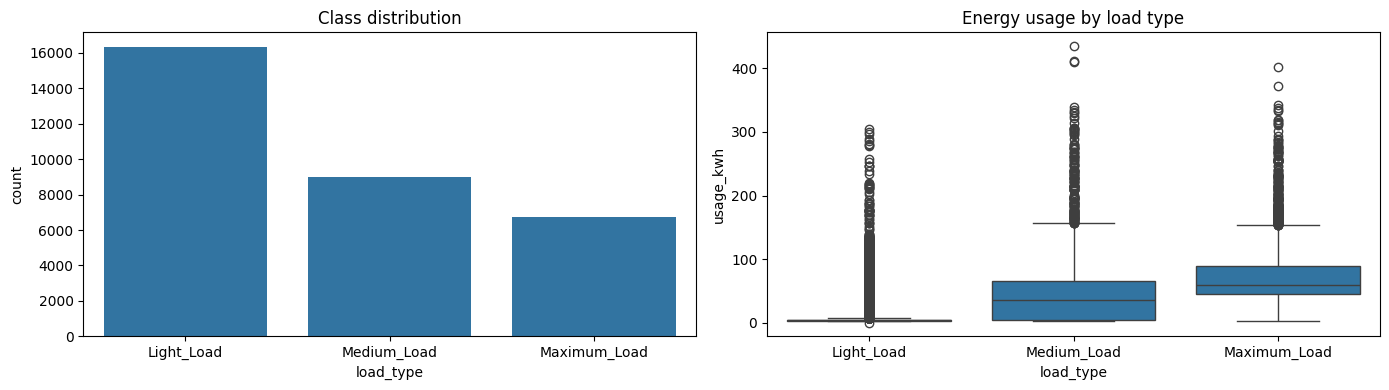

In [18]:
# ==========================================
# CELL 18: CLASS DISTRIBUTION AND ENERGY USAGE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# How many readings belong to each class
sns.countplot(x="load_type", data=eda_data, order=LABELS, ax=axes[0])
axes[0].set_title("Class distribution")

# Does energy usage differ between load types?
sns.boxplot(x="load_type", y="usage_kwh", data=eda_data, order=LABELS, ax=axes[1])
axes[1].set_title("Energy usage by load type")

plt.tight_layout()
plt.show()

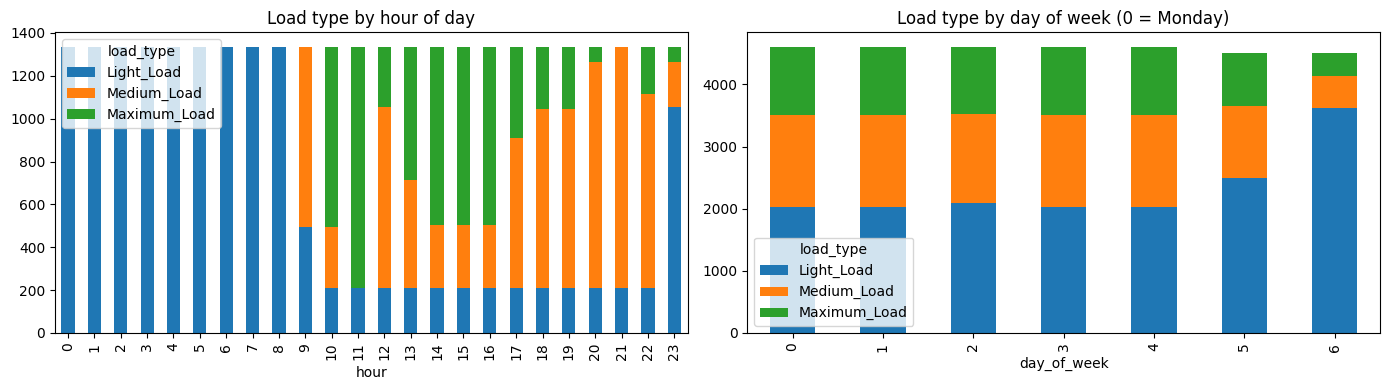

In [19]:
# ==========================================
# CELL 19: LOAD TYPE BY HOUR AND DAY OF WEEK
# ==========================================

# Count each load type per hour and per weekday to see if load follows a time schedule
counts_by_hour = pd.crosstab(eda_data["hour"], eda_data["load_type"])[LABELS]
counts_by_day = pd.crosstab(eda_data["day_of_week"], eda_data["load_type"])[LABELS]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
counts_by_hour.plot(kind="bar", stacked=True, ax=axes[0], title="Load type by hour of day")
counts_by_day.plot(kind="bar", stacked=True, ax=axes[1], title="Load type by day of week (0 = Monday)")
plt.tight_layout()
plt.show()

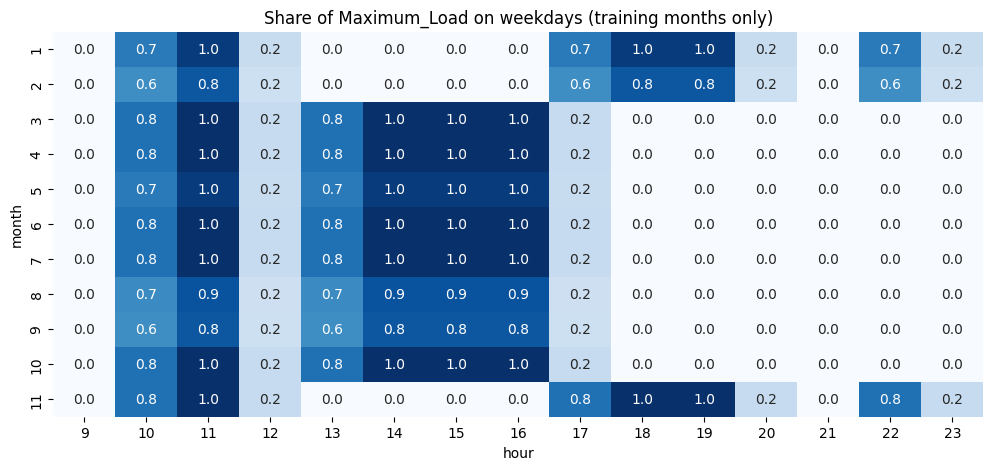

In [20]:
# ==========================================
# CELL 20: DOES THE SCHEDULE CHANGE BY MONTH?
# ==========================================

# Weekdays from the training period only
train_weekdays = eda_data[eda_data["day_of_week"] < 5].copy()

# 1 if the reading is Maximum_Load, else 0. The mean of this column = share of Maximum_Load.
train_weekdays["is_maximum"] = (train_weekdays["load_type"] == "Maximum_Load").astype(int)

maximum_share = train_weekdays.pivot_table(index="month", columns="hour", values="is_maximum", aggfunc="mean")

# Only daytime hours are shown, because 00:00-08:59 is always Light_Load
plt.figure(figsize=(12, 5))
sns.heatmap(maximum_share.loc[:, 9:23], cmap="Blues", annot=True, fmt=".1f", cbar=False)
plt.title("Share of Maximum_Load on weekdays (training months only)")
plt.show()

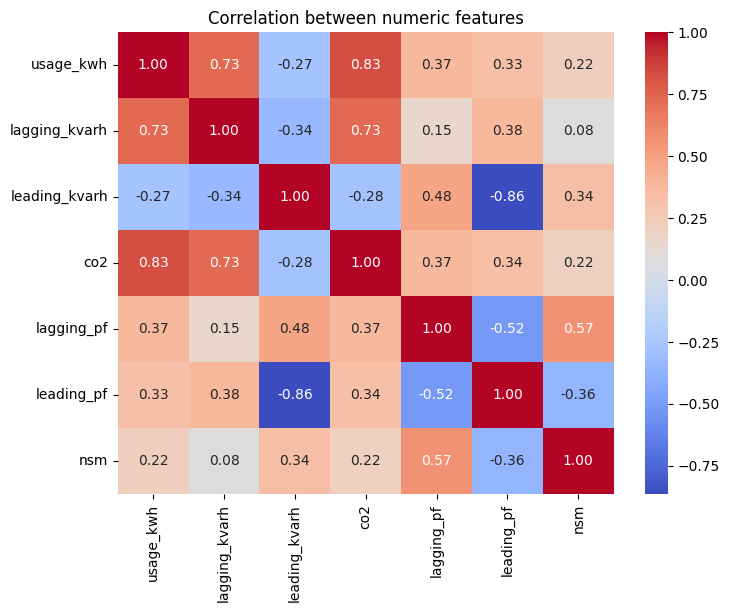

In [21]:
# ==========================================
# CELL 21: CORRELATION BETWEEN NUMERIC FEATURES
# ==========================================

# Check which features move together (strongly correlated features carry similar information)
numeric_columns = ["usage_kwh", "lagging_kvarh", "leading_kvarh", "co2", "lagging_pf", "leading_pf", "nsm"]

plt.figure(figsize=(8, 6))
sns.heatmap(eda_data[numeric_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between numeric features")
plt.show()

In [22]:
# ==========================================
# CELL 22: MEDIAN VALUES PER CLASS
# ==========================================

# Typical (median) value of each feature for each load type
eda_data.groupby("load_type")[numeric_columns].median().loc[LABELS].T

load_type,Light_Load,Medium_Load,Maximum_Load
usage_kwh,3.35,34.92,59.90
lagging_kvarh,4.75,5.69,28.51
leading_kvarh,0.00,0.36,0.00
co2,0.00,0.02,0.03
lagging_pf,63.45,96.81,91.56
leading_pf,100.00,99.99,100.00
nsm,21600.00,66600.00,52200.00


**EDA findings**
- **Load follows a time schedule.** 00:00-08:59 is always `Light_Load`, and weekends are mostly `Light_Load`.
  The time of a reading is always known when predicting, so using it is not leakage.
- **The schedule changes in winter.** All months have `Maximum_Load` around 10:00-11:59.
  After that, January, February and November have it at 17:00-19:59 and 22:00,
  while March-October have it at 13:00-16:59 instead.
- `Medium_Load` and `Maximum_Load` use much more energy than `Light_Load`.
- `co2` is strongly correlated with `usage_kwh` (about 0.83 in the training period), so it carries similar information.
  It is not target leakage, because it does not contain the load type.
- No column is created from `load_type`, so there is no direct target leakage.

## 7. Feature Engineering

**Why `is_winter`?** The training-period heatmap (cell above) shows two different daily schedules:
January, February and November vs March-October. The flag lets the model learn both.
December is **assumed** to follow the winter schedule because it sits between November and January.

**Note on how this feature was found:** the winter pattern was first noticed while investigating weak results
of an earlier draft of this project that had no season feature. The decision to keep it rests only on the
training-period evidence above, but because of this history the December score may be slightly optimistic.

In [23]:
# ==========================================
# CELL 23: FEATURE ENGINEERING
# ==========================================

# Weekends have much lower load, so we give the model a simple weekend flag
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# The training-period heatmap showed Jan, Feb and Nov follow a different schedule from Mar-Oct.
# December is treated as winter because it sits between November and January (an assumption).
# Winter months exist in the training data, so the model can learn this pattern.
df["is_winter"] = df["month"].isin([11, 12, 1, 2]).astype(int)

# Features used by the model.
# - hour is not included because nsm already contains the time of day.
# - month is not included because December (12) never appears in training,
#   so the model could not learn anything from it.
features = ["usage_kwh", "lagging_kvarh", "leading_kvarh", "co2",
            "lagging_pf", "leading_pf", "nsm", "day_of_week", "is_weekend", "is_winter"]
target = "load_type"

## 8. Train/Test Split

As required: **train = 2018-01-01 00:00 to 2018-11-30 23:59, test = 2018-12-01 00:00 to 2018-12-31 23:59**.
The split uses explicit date ranges. A random split is not used, because it would let the model train on
readings from after the test period.

In [24]:
# ==========================================
# CELL 24: TRAIN TEST SPLIT
# ==========================================

# Split by date range: the last month (December 2018) is the test set
is_train_period = (df["date_time"] >= TRAIN_START) & (df["date_time"] <= TRAIN_END)
is_test_period = (df["date_time"] >= TEST_START) & (df["date_time"] <= TEST_END)
train_data = df[is_train_period]
test_data = df[is_test_period]

# Only the 2019-01-01 00:00 reading should be outside both periods
print("Rows outside both periods:")
print(df.loc[~is_train_period & ~is_test_period, ["date_time", "load_type"]])
print()

X_train = train_data[features]
y_train = train_data[target]
X_test = test_data[features]
y_test = test_data[target]

print("Train:", X_train.shape, "from", train_data["date_time"].min(), "to", train_data["date_time"].max())
print("Test: ", X_test.shape, "from", test_data["date_time"].min(), "to", test_data["date_time"].max())

# Compare class balance in train and test
print()
print("Class share in train:")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Class share in test:")
print(y_test.value_counts(normalize=True).round(3))

Rows outside both periods:
       date_time   load_type
35039 2019-01-01  Light_Load

Train: (32063, 10) from 2018-01-01 00:15:00 to 2018-11-30 23:45:00
Test:  (2976, 10) from 2018-12-01 00:00:00 to 2018-12-31 23:45:00

Class share in train:
load_type
Light_Load      0.509
Medium_Load     0.280
Maximum_Load    0.210
Name: proportion, dtype: float64

Class share in test:
load_type
Light_Load      0.586
Medium_Load     0.237
Maximum_Load    0.177
Name: proportion, dtype: float64


## 9. Preprocessing and Model Training

**Preprocessing:** missing values are filled with the median, and logistic regression also needs scaling.

**Why a Pipeline?** The median (and the scaler) must be learned from training data only.
During cross-validation the training data changes in every fold, so these steps must be re-fitted in each fold.
A `Pipeline` does this automatically and prevents leakage.

**Is scaling needed?**
- Logistic Regression: yes. It is sensitive to feature size (`nsm` goes up to ~86,000, `co2` is below 1).
  An unscaled version is included to show the difference with evidence.
- Decision Tree, Random Forest, Gradient Boosting: no. Tree splits do not depend on feature scale.

**Baseline:** always predicts the most common class. Every real model must beat it.

In [25]:
# ==========================================
# CELL 25: DEFINE MODELS
# ==========================================

# Each model is a pipeline: fill missing values -> (scale) -> classifier
models = {
    "Baseline (most frequent)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic Regression (no scaling)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Logistic Regression (scaled)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000)),
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
}

**How the models are trained and compared:** December is **not** used here.
We use `TimeSeriesSplit` cross-validation on January-November only:
each fold trains on earlier data and validates on the period right after it, like real forecasting.

In [26]:
# ==========================================
# CELL 26: CROSS-VALIDATION ON TRAINING DATA
# ==========================================

# 5 time-ordered folds: always train on the past, validate on the future
cv = TimeSeriesSplit(n_splits=5)

cv_results_list = []
for model_name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])

    # Average the scores over the 5 folds
    cv_results_list.append({
        "model": model_name,
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_f1_macro": scores["test_f1_macro"].mean(),
        "cv_f1_macro_std": scores["test_f1_macro"].std(),
    })

In [27]:
# ==========================================
# CELL 27: CHECK THE CROSS-VALIDATION FOLDS
# ==========================================

# Print the dates in each fold to understand why some folds score lower than others
for fold_number, (train_index, validation_index) in enumerate(cv.split(X_train)):
    fold_train_end = train_data["date_time"].iloc[train_index].max().date()
    validation_start = train_data["date_time"].iloc[validation_index].min().date()
    validation_end = train_data["date_time"].iloc[validation_index].max().date()
    print("Fold", fold_number, "| train up to", fold_train_end,
          "| validate", validation_start, "to", validation_end)

Fold 0 | train up to 2018-02-25 | validate 2018-02-25 to 2018-04-22
Fold 1 | train up to 2018-04-22 | validate 2018-04-22 to 2018-06-17
Fold 2 | train up to 2018-06-17 | validate 2018-06-17 to 2018-08-11
Fold 3 | train up to 2018-08-11 | validate 2018-08-11 to 2018-10-06
Fold 4 | train up to 2018-10-06 | validate 2018-10-06 to 2018-11-30


Fold 0 trains only on January-February (winter schedule) and validates on late February to April (mostly non-winter schedule),
which the model has not seen yet. This makes the fold-to-fold spread (standard deviation) large.
Later folds contain both seasons in training.

## 10. Model Comparison

In [28]:
# ==========================================
# CELL 28: COMPARE ALL MODELS
# ==========================================

# Cross-validation results on January-November, best macro F1 first
model_results = pd.DataFrame(cv_results_list).round(3)
model_results = model_results.sort_values("cv_f1_macro", ascending=False).reset_index(drop=True)
model_results

,model,cv_accuracy,cv_f1_macro,cv_f1_macro_std
0,Gradient Boosting,0.897,0.880,0.145
1,Random Forest,0.889,0.870,0.140
2,Decision Tree,0.887,0.869,0.141
3,Logistic Regression (scaled),0.744,0.689,0.078
4,Logistic Regression (no scaling),0.691,0.634,0.083
5,Baseline (most frequent),0.501,0.222,0.005


In [29]:
# ==========================================
# CELL 29: SELECT THE BEST MODEL
# ==========================================

# The model with the highest cross-validation macro F1 is selected.
# December has not been used yet, so it stays a fair, unseen test.
best_model_name = model_results.loc[0, "model"]
print("Selected model:", best_model_name)

Selected model: Gradient Boosting


**Does treating the corrupted values help?** (decided with cross-validation on Jan-Nov only)

We mark rows where the power factor formula is off by more than 1 point as missing
(energy, reactive power and power factor of that row), and repeat cross-validation for the selected model.

In [30]:
# ==========================================
# CELL 30: TEST TREATMENT OF CORRUPTED VALUES (CV ONLY)
# ==========================================

# Copy of the training features where inconsistent readings are set to missing
treated_X_train = X_train.copy()

for side in ["lagging", "leading"]:
    usage = treated_X_train["usage_kwh"]
    kvarh = treated_X_train[side + "_kvarh"]
    expected_pf = 100 * usage / (usage ** 2 + kvarh ** 2) ** 0.5
    inconsistent = (expected_pf - treated_X_train[side + "_pf"]).abs() > 1
    print(side, "rows marked as missing:", inconsistent.sum())
    treated_X_train.loc[inconsistent, ["usage_kwh", side + "_kvarh", side + "_pf"]] = None

# Same model, same folds - only the training data is different
treated_scores = cross_validate(models[best_model_name], treated_X_train, y_train, cv=cv, scoring="f1_macro")

print()
print("CV macro F1 without treatment:", model_results.loc[0, "cv_f1_macro"])
print("CV macro F1 with treatment:   ", round(treated_scores["test_score"].mean(), 3))

lagging rows marked as missing: 4053
leading rows marked as missing: 1623



CV macro F1 without treatment: 0.88
CV macro F1 with treatment:    0.882


**Decision: the treatment is not applied.** It changes CV macro F1 only from 0.880 to 0.882, which is much
smaller than the variation between folds, while it would mark the values of about 5,700 rows as missing.
The corrupted values are kept and documented as a known limitation of the data.

## 11. Final Model

The selected model is trained once on **all** of January-November.

In [31]:
# ==========================================
# CELL 31: TRAIN THE FINAL MODEL
# ==========================================

# Fit the selected pipeline on the full training period (Jan-Nov).
# The imputer learns its medians from this training data only.
final_model = models[best_model_name]
final_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model', HistGradientBoostingClassifier(random_state=42))])

## 12. Evaluation on December (Test Set)

This is the first and only time December is used.
Macro averages are used so each of the 3 classes counts equally.

In [32]:
# ==========================================
# CELL 32: TEST SET METRICS
# ==========================================

# Predict the load type for every December reading
predictions = final_model.predict(X_test)

print("Model:", best_model_name)
print("Accuracy:         ", round(accuracy_score(y_test, predictions), 3))
print("Precision (macro):", round(precision_score(y_test, predictions, average="macro"), 3))
print("Recall (macro):   ", round(recall_score(y_test, predictions, average="macro"), 3))
print("F1-score (macro): ", round(f1_score(y_test, predictions, average="macro"), 3))
print()

# Precision, recall and F1 for each class
print(classification_report(y_test, predictions, labels=LABELS, digits=3))

Model: Gradient Boosting
Accuracy:          0.953
Precision (macro): 0.956
Recall (macro):    0.938
F1-score (macro):  0.947

              precision    recall  f1-score   support

  Light_Load      0.948     0.974     0.961      1744
 Medium_Load      0.969     0.945     0.957       704
Maximum_Load      0.952     0.896     0.923       528

    accuracy                          0.953      2976
   macro avg      0.956     0.938     0.947      2976
weighted avg      0.953     0.953     0.953      2976



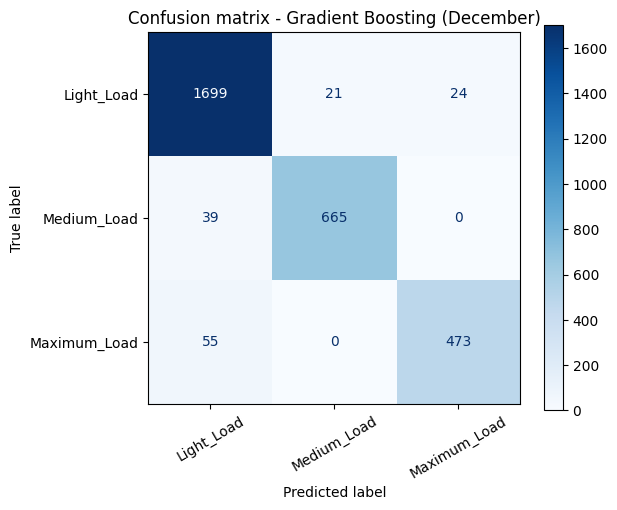

In [33]:
# ==========================================
# CELL 33: CONFUSION MATRIX
# ==========================================

# Rows = actual class, columns = predicted class. Shows which classes get mixed up.
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=LABELS, ax=ax, cmap="Blues")
ax.set_title("Confusion matrix - " + best_model_name + " (December)")
plt.xticks(rotation=30)
plt.show()

In [34]:
# ==========================================
# CELL 34: DECEMBER SCHEDULE CHECK (AFTER FINAL EVALUATION)
# ==========================================

# This check is done AFTER the final evaluation and was not used for any decision.
# It checks the assumption behind is_winter: does December follow the winter schedule?
december_weekdays = test_data[test_data["day_of_week"] < 5].copy()
december_weekdays["is_maximum"] = (december_weekdays["load_type"] == "Maximum_Load").astype(int)
december_share = december_weekdays.groupby("hour")["is_maximum"].mean()

# Share of Maximum_Load per hour: winter months in training vs December
winter_share = maximum_share.loc[[1, 2, 11]].mean()
comparison = pd.DataFrame({"winter months (train)": winter_share, "December (test)": december_share})
comparison.loc[9:23].round(2).T

hour,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
winter months (train),0.0,0.70,0.94,0.23,0.0,0.0,0.0,0.0,0.70,0.94,0.94,0.23,0.0,0.70,0.23
December (test),0.0,0.68,0.90,0.23,0.0,0.0,0.0,0.0,0.68,0.90,0.90,0.23,0.0,0.68,0.23


December follows the same schedule as the winter training months, so the `is_winter` assumption holds.
This was checked only after the final evaluation.

## 13. Feature Importance

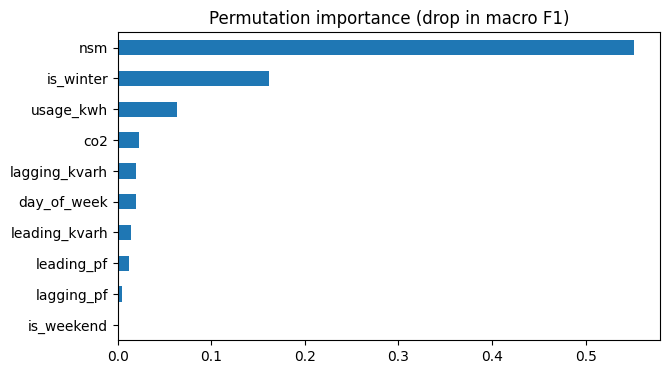

In [35]:
# ==========================================
# CELL 35: FEATURE IMPORTANCE
# ==========================================

# Permutation importance: shuffle one feature at a time and measure how much macro F1 drops.
# A big drop means the model relies on that feature.
# It is calculated on the training data because is_winter is always 1 in December,
# so shuffling it on December data would always show zero importance.
importance_result = permutation_importance(final_model, X_train, y_train, scoring="f1_macro",
                                           n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

feature_importance = pd.Series(importance_result.importances_mean, index=features).sort_values()
feature_importance.plot(kind="barh", figsize=(7, 4), title="Permutation importance (drop in macro F1)")
plt.show()

## 14. Prediction

In [36]:
# ==========================================
# CELL 36: EXAMPLE PREDICTIONS
# ==========================================

# Predict a few random December readings and compare with the actual load type
example_rows = test_data.sample(8, random_state=RANDOM_STATE)

example_predictions = pd.DataFrame({
    "date_time": example_rows["date_time"],
    "usage_kwh": example_rows["usage_kwh"],
    "actual": example_rows[target],
    "predicted": final_model.predict(example_rows[features]),
})
example_predictions

,date_time,usage_kwh,actual,predicted
34467,2018-12-26 01:00:00,3.31,Light_Load,Light_Load
34929,2018-12-30 20:30:00,3.24,Light_Load,Light_Load
34838,2018-12-29 21:45:00,3.46,Light_Load,Light_Load
32570,2018-12-06 06:45:00,3.31,Light_Load,Light_Load
33888,2018-12-20 00:15:00,4.03,Light_Load,Light_Load
33299,2018-12-13 21:00:00,20.16,Medium_Load,Medium_Load
32748,2018-12-08 03:15:00,3.96,Light_Load,Light_Load
33273,2018-12-13 14:30:00,72.61,Medium_Load,Medium_Load


In [37]:
# ==========================================
# CELL 37: FINAL SUMMARY
# ==========================================

# Summary of the final model: validation score (Jan-Nov) and test score (December)
print("Final model:", best_model_name)
print("CV macro F1 (Jan-Nov):   ", model_results.loc[0, "cv_f1_macro"])
print("Test accuracy (December):", round(accuracy_score(y_test, predictions), 3))
print("Test macro F1 (December):", round(f1_score(y_test, predictions, average="macro"), 3))

Final model: Gradient Boosting
CV macro F1 (Jan-Nov):    0.88
Test accuracy (December): 0.953
Test macro F1 (December): 0.947


## 15. Conclusion

- **Cleaning:** midnight timestamps moved to the correct day, corrupted `NSM` recalculated from the timestamp,
  power factors above 100% set to missing, missing values filled with the training median (inside the pipeline),
  one corrupted duplicate removed. About 4-10% of energy/reactive power values are corrupted (about 2x too high);
  treating them was tested with cross-validation and not applied, because it gave no meaningful improvement.
- **Key insight:** load type follows a time schedule that changes between winter (Nov-Feb) and the rest of the year.
  The `is_winter` flag lets the model learn the correct schedule for December.
- **Leakage prevention:** time-based split, imputer/scaler inside a Pipeline, and model selection using
  cross-validation on January-November only. December was used once, for the final evaluation.
- **Model choice:** in cross-validation, tree-based models clearly beat the baseline and logistic regression.
  The model with the best cross-validation macro F1 was selected. Random Forest and Decision Tree are close behind,
  so a Decision Tree is a reasonable choice if explaining the rules matters more.
- **Scaling:** only helps logistic regression; tree models do not need it.
- **Limitations:** one year of data and one test month. December is assumed to follow the winter schedule,
  and the winter pattern was first noticed while investigating an earlier draft, so the December score may be
  slightly optimistic.
  Most remaining errors are `Medium_Load` / `Maximum_Load` readings predicted as `Light_Load`.